# Data Understanding file 2

In [62]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

data_frame = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")

data_frame

,hadm_id,charttime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,___,198.00,IU/L,29.0,201.00,NaN,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5,5.00,ng/mL,0.0,10.00,NaN,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,___,0.03,ng/mL,0.0,0.01,abnormal,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.2,1.20,NaN,0.9,1.10,abnormal,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.8,12.80,sec,9.4,12.50,abnormal,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180,180.00,K/uL,150.0,400.00,NaN,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.5,14.50,%,10.5,15.50,NaN,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,3.26,m/uL,3.9,5.20,abnormal,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.4,8.40,K/uL,4.0,10.00,NaN,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [63]:
# Shows how many rows and columns the dataset has
print("Dataset shape (rows, columns):", data_frame.shape)


Dataset shape (rows, columns): (978503, 14)


In [64]:
# Uses the get_cols() function from data_understanding.py to list all columns
print("List of column names:\n")
print(du.get_cols(data_frame))

List of column names:

['hadm_id', 'charttime', 'value', 'valuenum', 'valueuom', 'ref_range_lower', 'ref_range_upper', 'flag', 'label', 'fluid', 'examination_group', 'analysis_batch_id', 'qc_flag', 'ref_range']


In [65]:
print("Data types of each column:\n")
print(du.get_types(data_frame))


Data types of each column:

hadm_id              float64
charttime             object
value                 object
valuenum             float64
valueuom              object
ref_range_lower      float64
ref_range_upper      float64
flag                  object
label                 object
fluid                 object
examination_group     object
analysis_batch_id     object
qc_flag               object
ref_range             object
dtype: object


TOMMASO QUI SOTTO HO AGGIUNTO LA STAMPA DELLE RIGHE DUPLICATE, da aggiungere nel main alla function del numero dei duplicati

In [66]:
num_dups = du.get_num_dups(data_frame)
print(f"Number of duplicated rows: {num_dups}")

# Shows which rows are duplicated (if any)
if num_dups > 0:
    print("\nList of duplicated rows:\n")
    print(data_frame[data_frame.duplicated(keep=False)])
else:
    print("\nNo duplicated rows found.")


Number of duplicated rows: 2

List of duplicated rows:

           hadm_id            charttime value  valuenum valueuom  \
337781  22665778.0  2114-06-25 17:44:00   NaN       NaN      NaN   
337786  22665778.0  2114-06-25 17:44:00   NaN       NaN      NaN   
926329  27638257.0  2189-04-21 16:00:00   NaN       NaN      NaN   
926331  27638257.0  2189-04-21 16:00:00   NaN       NaN      NaN   

        ref_range_lower  ref_range_upper flag                       label  \
337781              NaN              NaN  NaN  Length of Urine Collection   
337786              NaN              NaN  NaN  Length of Urine Collection   
926329              NaN              NaN  NaN  Length of Urine Collection   
926331              NaN              NaN  NaN  Length of Urine Collection   

        fluid examination_group analysis_batch_id qc_flag ref_range  
337781  Urine        Urine Test   BATCH_211406_T7      OK       NaN  
337786  Urine        Urine Test   BATCH_211406_T7      OK       NaN  
926329 

In [67]:
print("Columns containing at least one NaN value:\n")
print(du.get_cols_with_none(data_frame))

Columns containing at least one NaN value:

hadm_id              False
charttime            False
value                 True
valuenum              True
valueuom              True
ref_range_lower       True
ref_range_upper       True
flag                  True
label                False
fluid                False
examination_group    False
analysis_batch_id    False
qc_flag              False
ref_range             True
dtype: bool


In [68]:
def get_none_percentage_per_cols(data_frame):
    res = []
    cols = du.get_cols(data_frame)
    rows = data_frame.shape[0]
    for col in cols:
        not_none = (data_frame[col].count())
        none_percentage = ((rows - not_none)/rows)*100
        res.append((col, none_percentage))
    return res
# Get the percentage of None values for each columns
none_percentage_per_cols = []

print("PERCENTAGE OF NONE PER COLUMN")
for col, percentage in sorted(get_none_percentage_per_cols(data_frame), key=lambda tup: tup[1], reverse=True):
    print(f"{col}: {percentage:.2f}%")

PERCENTAGE OF NONE PER COLUMN
ref_range: 85.06%
flag: 64.88%
ref_range_lower: 11.54%
ref_range_upper: 11.54%
valueuom: 9.60%
valuenum: 7.27%
value: 4.55%
hadm_id: 0.00%
charttime: 0.00%
label: 0.00%
fluid: 0.00%
examination_group: 0.00%
analysis_batch_id: 0.00%
qc_flag: 0.00%


NUMBER OF MISSING (none) VALUES PER COLUMN:

ref_range            832288
flag                 634816
ref_range_lower      112959
ref_range_upper      112959
valueuom              93918
valuenum              71186
value                 44478
hadm_id                   0
charttime                 0
label                     0
fluid                     0
examination_group         0
analysis_batch_id         0
qc_flag                   0
dtype: int64


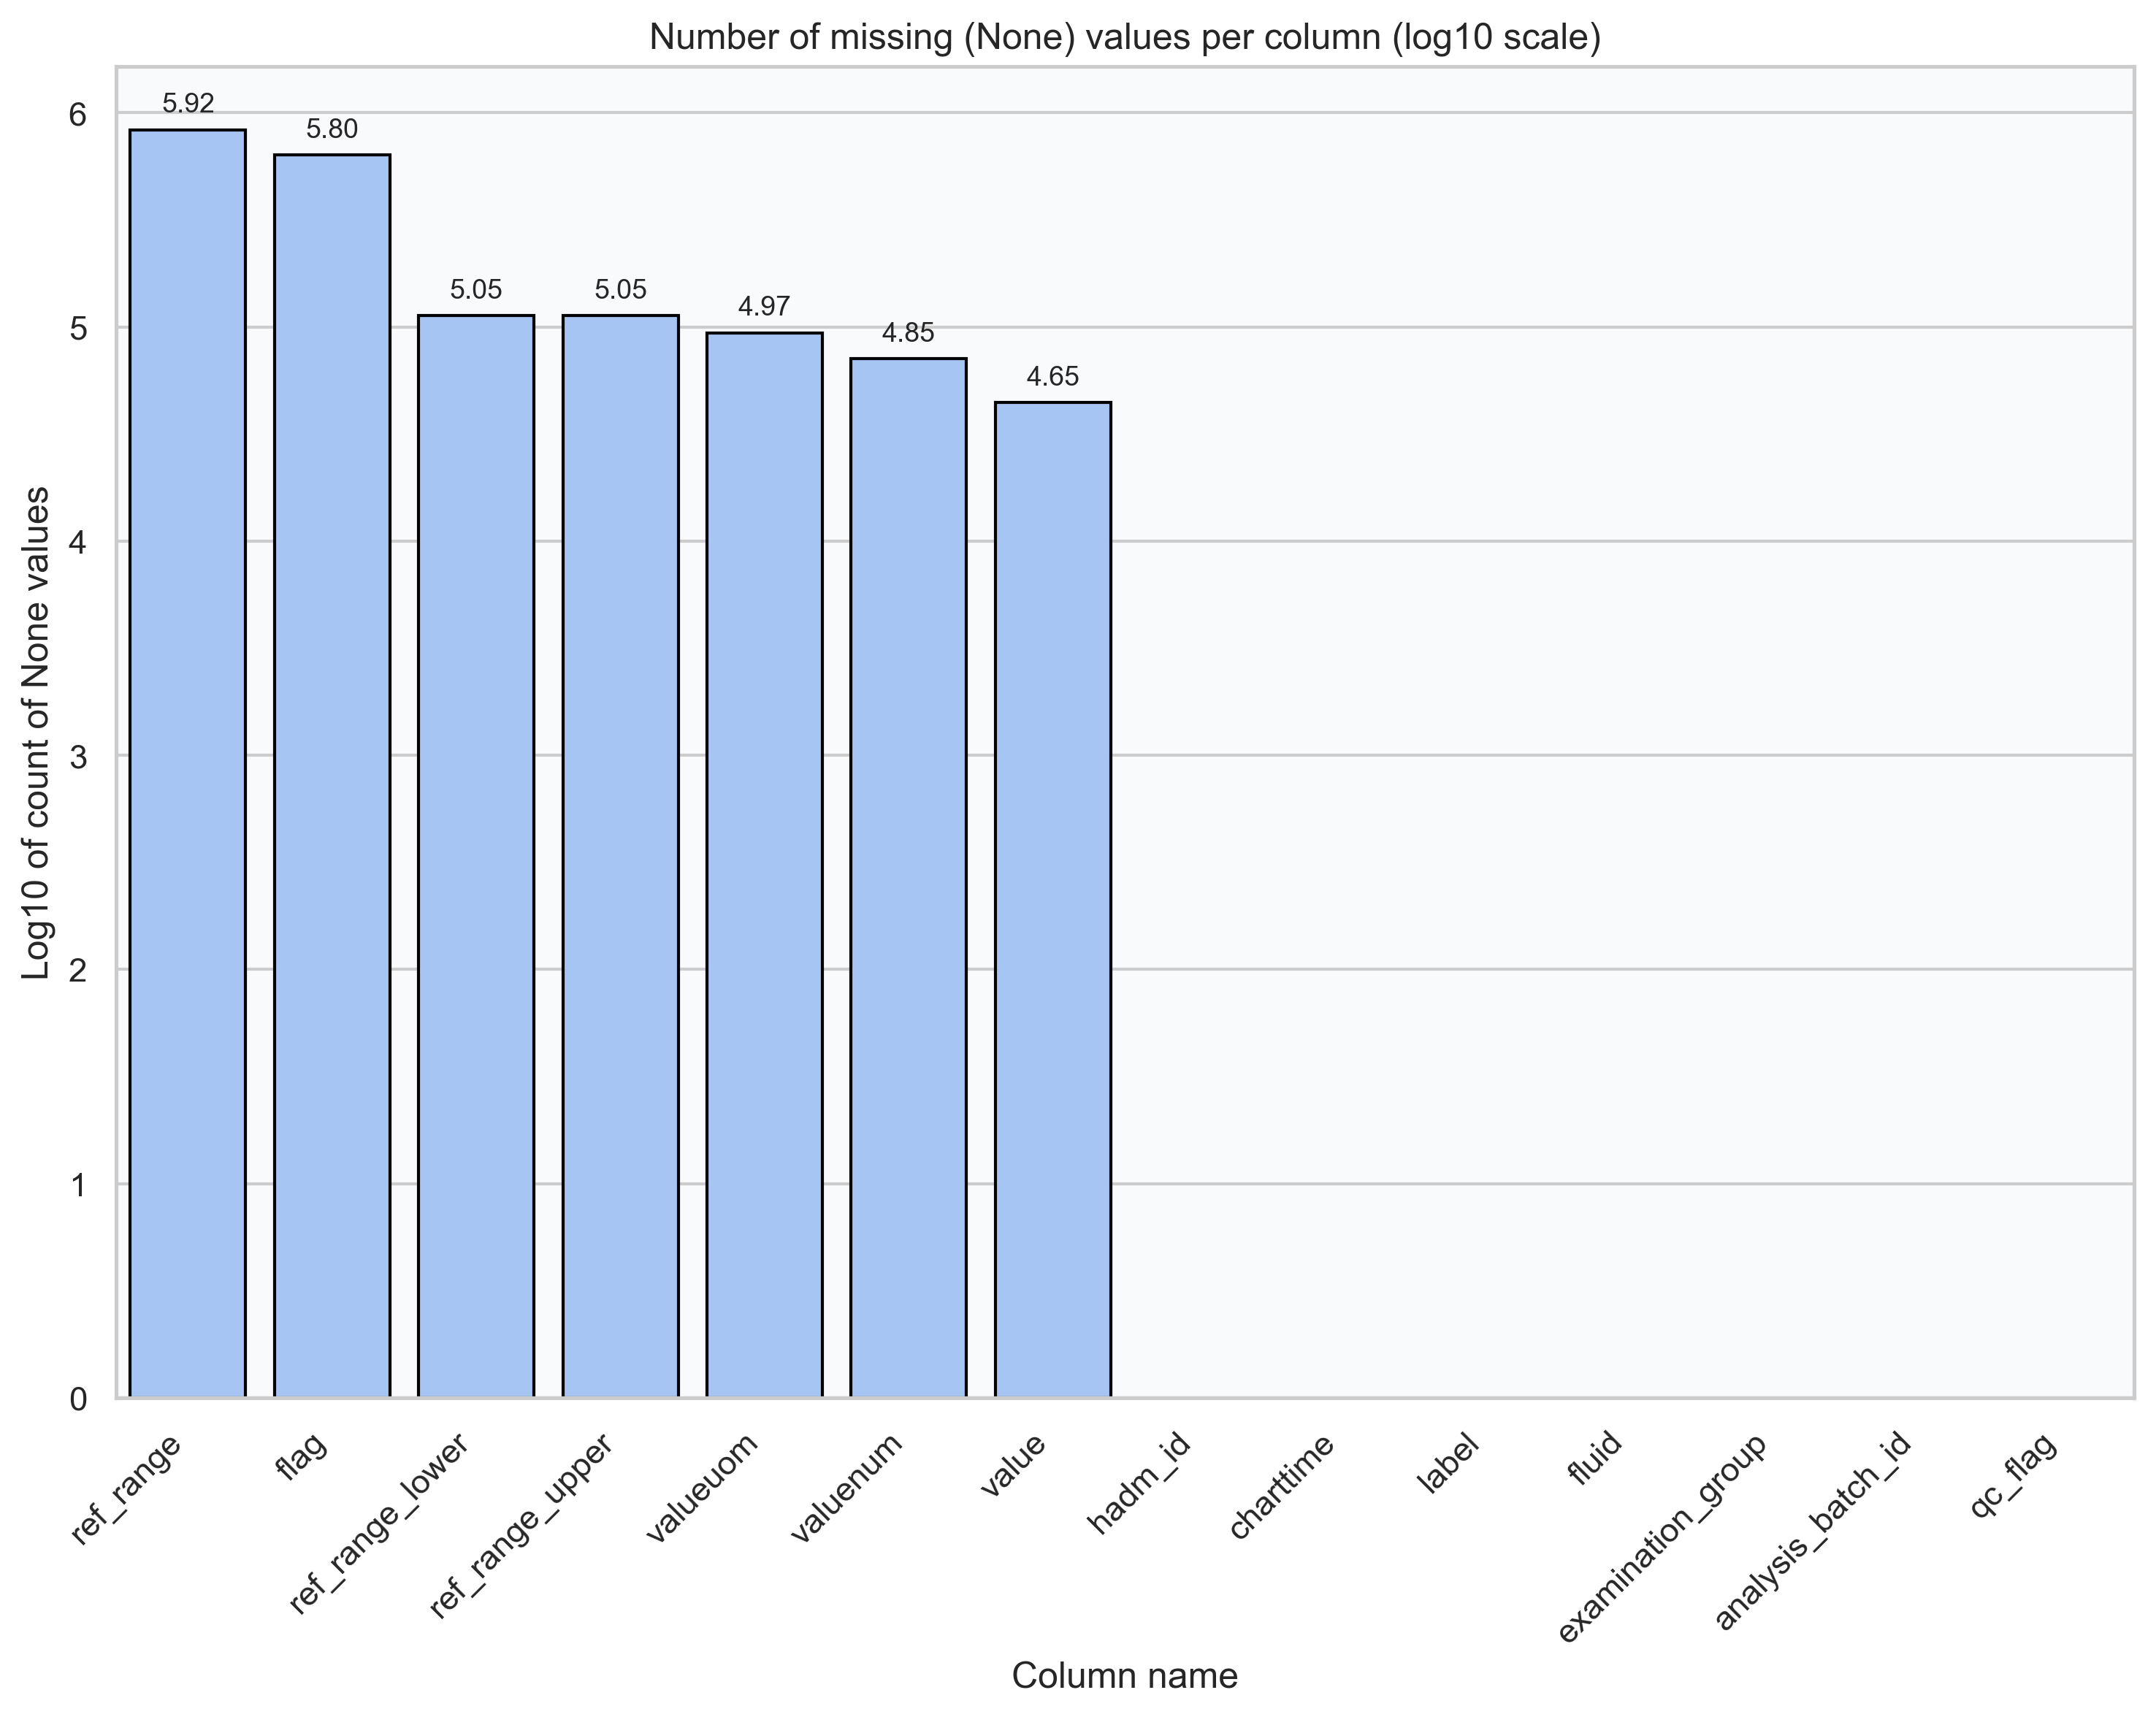

In [69]:
# Count of None (NaN) values per column
print("NUMBER OF MISSING (none) VALUES PER COLUMN:\n")
none_counts = data_frame.isna().sum().sort_values(ascending=False)
print(none_counts)

none_counts_log = np.log10(none_counts.replace(0, np.nan))

none_df = none_counts_log.reset_index()
none_df.columns = ["column", "log10_count"]

fig, ax = plt.subplots(figsize=(10,8), dpi=300)
sns.barplot(data=none_df, x="column", y="log10_count", color="#99c2ff", edgecolor="black")

plt.title("Number of missing (None) values per column (log10 scale)")
plt.xlabel("Column name")
plt.ylabel("Log10 of count of None values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
# Add value labels on top of bars
for i, v in enumerate(none_df["log10_count"]):
    if not np.isnan(v):  # evita etichette per colonne senza None
        ax.text(i, v + max(none_df["log10_count"]) * 0.01, 
                f"{v:.2f}", ha="center", va="bottom", fontsize=9)
plt.show()


In [70]:
numeric_cols = du.get_numeric_cols(data_frame)

print("Numeric columns selected for analysis:\n")
print(numeric_cols)

print("\nDescriptive statistics for numeric columns:\n")
print(du.get_basic_stats(data_frame))


Numeric columns selected for analysis:

['valuenum', 'ref_range_lower', 'ref_range_upper']

Descriptive statistics for numeric columns:

            valuenum  ref_range_lower  ref_range_upper
count  907317.000000    865544.000000    865544.000000
mean       67.332325        31.724619        55.794861
std      2175.589189        44.840840       400.515033
min      -743.000000         0.000000         0.000000
25%         4.300000         3.300000         5.400000
50%        17.000000        10.400000        20.000000
75%        60.200000        36.000000        52.000000
max    886449.000000      2200.000000    100000.000000


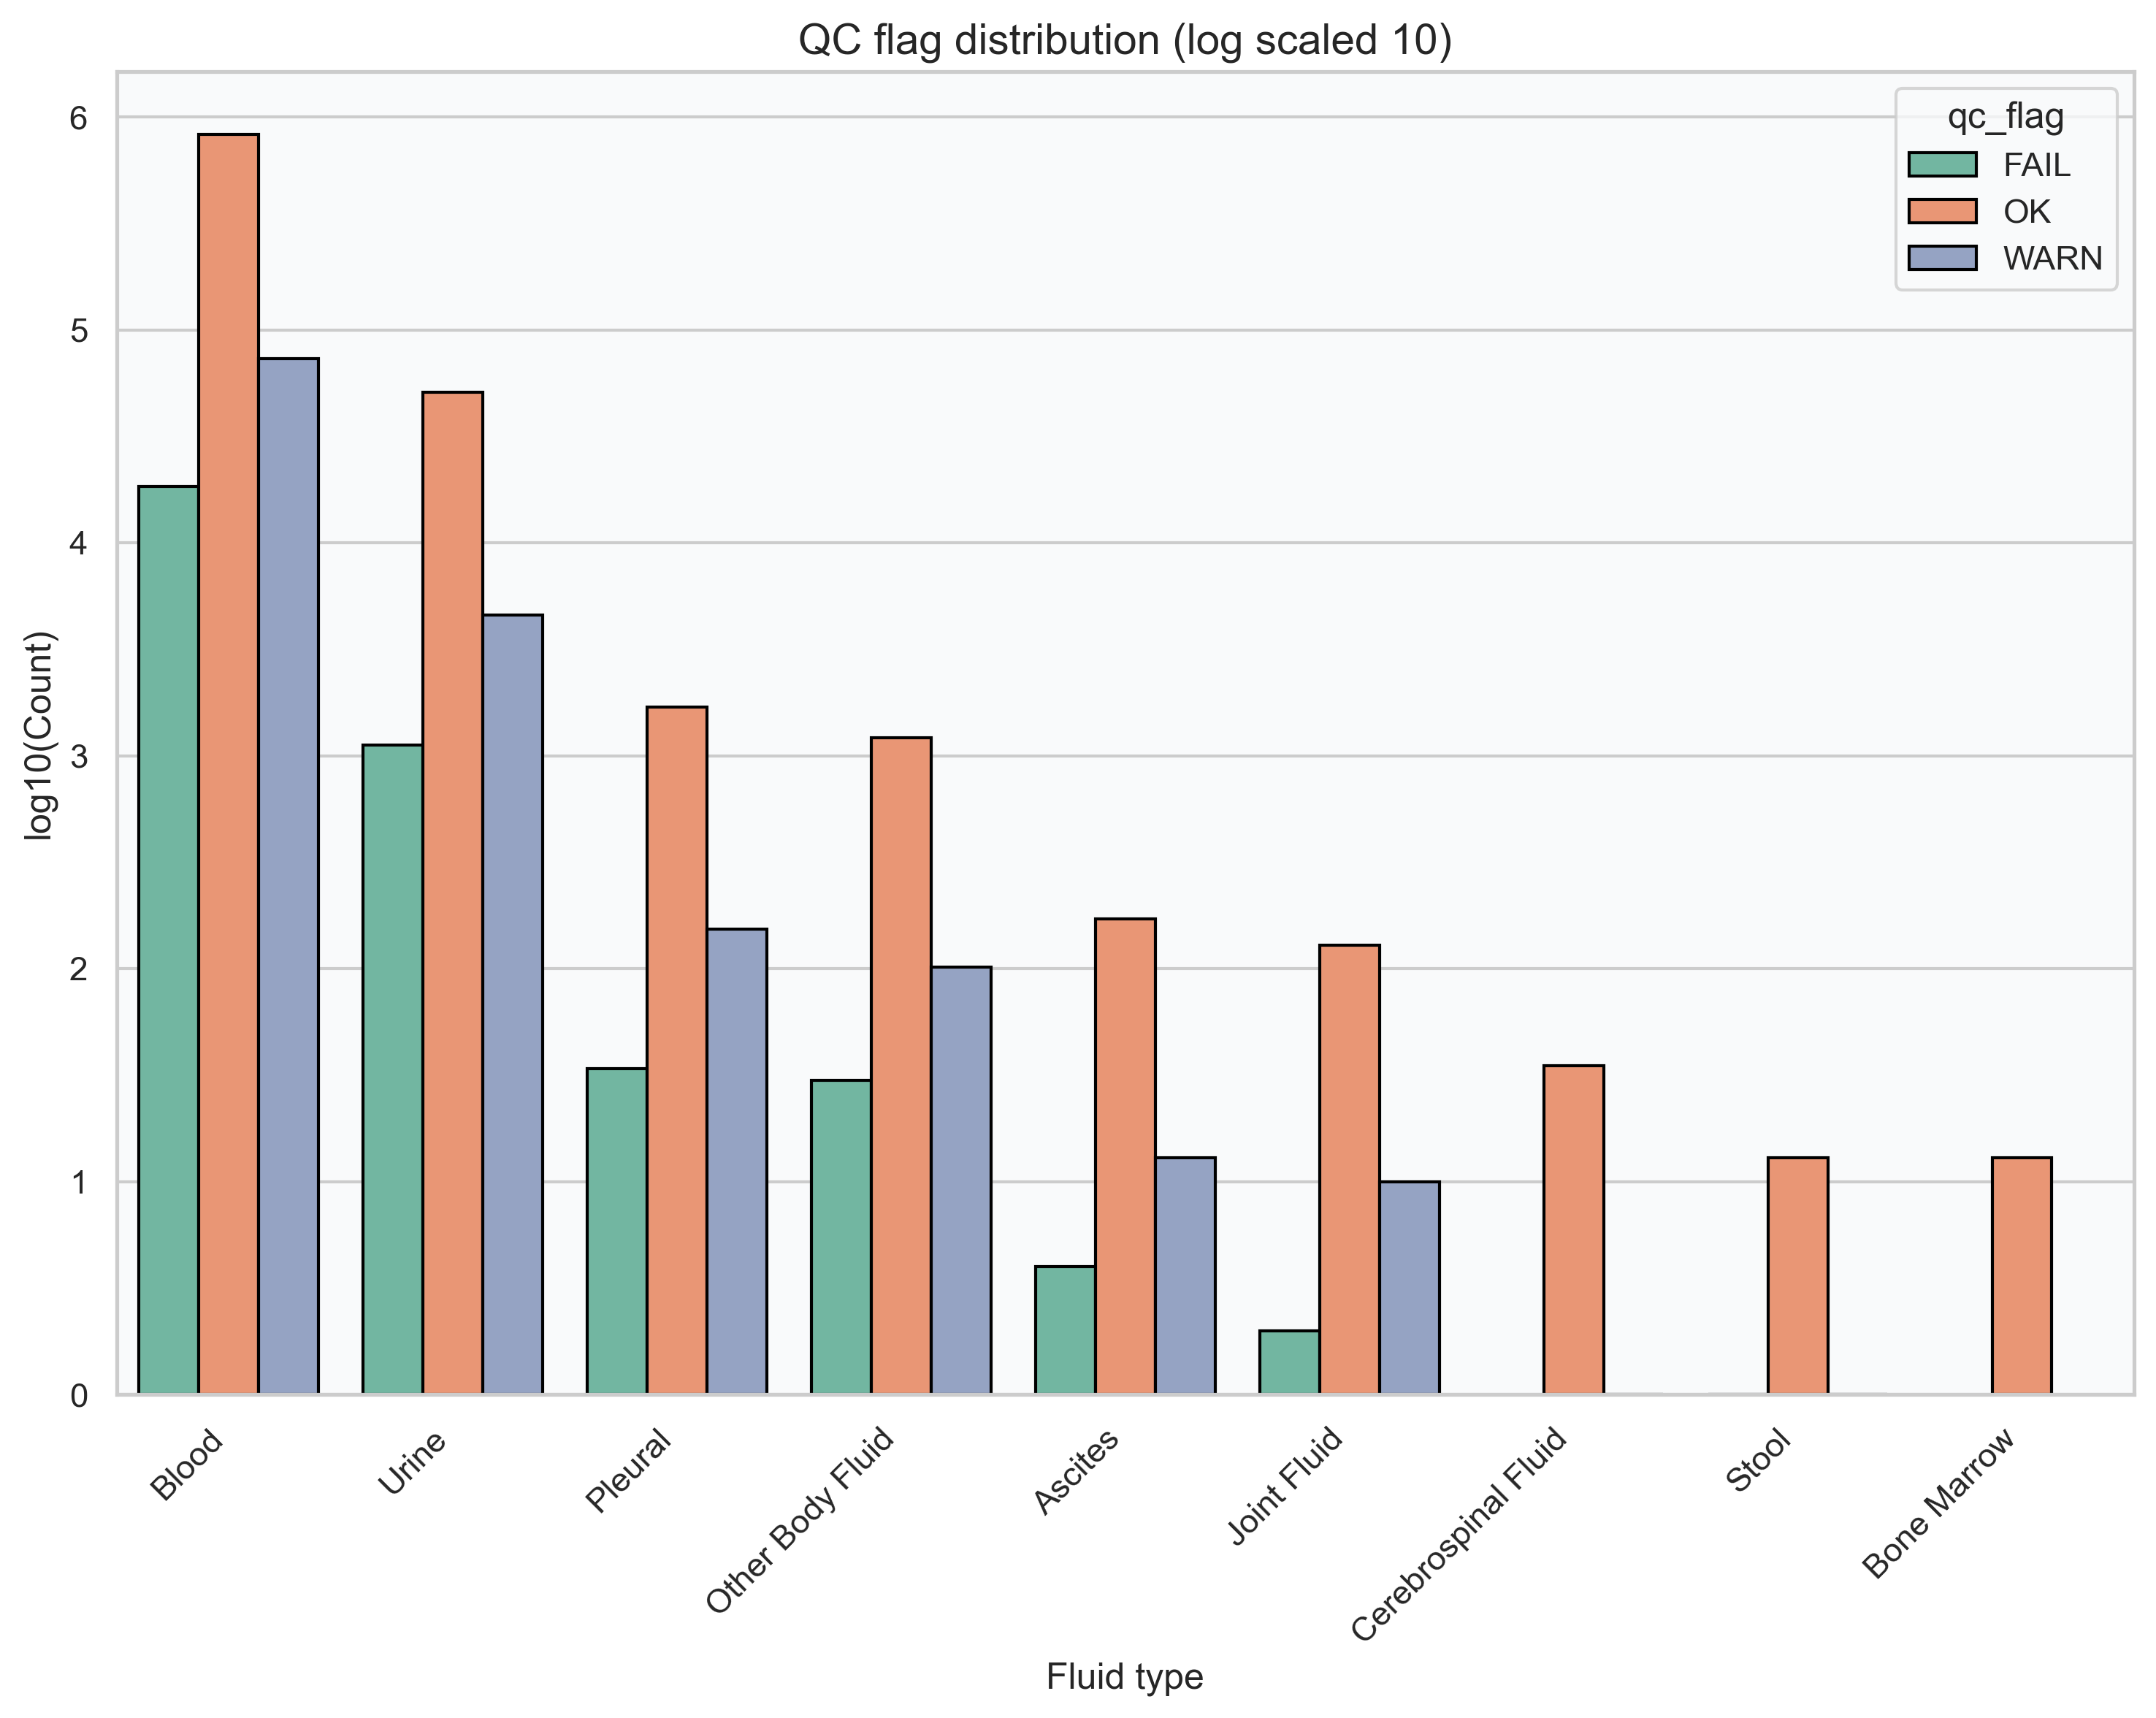

In [71]:
counts = (
    data_frame.groupby(["fluid", "qc_flag"])
    .size()
    .reset_index(name="count")
)

counts = counts[counts["count"] > 0]
fluid_order = (
    counts.groupby("fluid")["count"]
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

counts["log_count"] = np.log10(counts["count"])

plt.figure(figsize=(10,8), dpi=300)
ax = sns.barplot(
    data=counts,
    x="fluid",
    y="log_count",
    hue="qc_flag",
    order=fluid_order,
    palette="Set2",
    edgecolor="black",
)

plt.title('QC flag distribution (log scaled 10)', fontsize=14)
plt.xlabel('Fluid type')
plt.ylabel('log10(Count)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

In [72]:
required_cols = {"hadm_id", "flag"}

if required_cols.issubset(data_frame.columns):
    # filter rows with flag = "abnormal"
    df_abnormal = (
        data_frame[data_frame["flag"] == "abnormal"]
        .groupby("hadm_id")
        .size()
        .sort_values(ascending=False)
    )

    print("Number of abnormal lab values per hadm_id:\n")
    print(df_abnormal)
else:
    print("Columns required for abnormal value analysis are missing.")


Number of abnormal lab values per hadm_id:

hadm_id
26941902.0    2142
21332395.0    1699
28062533.0    1423
27261448.0    1167
29018732.0    1122
              ... 
29894473.0       1
29409625.0       1
20933002.0       1
20538777.0       1
27582745.0       1
Length: 4735, dtype: int64


In [73]:
bins = [0, 1, 10, 500, 1000, 1500, df_abnormal.max()]
labels = ["=1", "2–10", "11–500", "501–1000", "1001–1500", ">1500"]

categories = pd.cut(df_abnormal.values, bins=bins, labels=labels, include_lowest=True)

# how many hamd_id has tot flag="abnormal"
distribution = pd.Series(categories).value_counts(sort=False)

print("Distribuzione per fasce del numero di valori anomali per ammissione:\n")
print(distribution)


Distribuzione per fasce del numero di valori anomali per ammissione:

=1             25
2–10          511
11–500       4158
501–1000       34
1001–1500       5
>1500           2
Name: count, dtype: int64


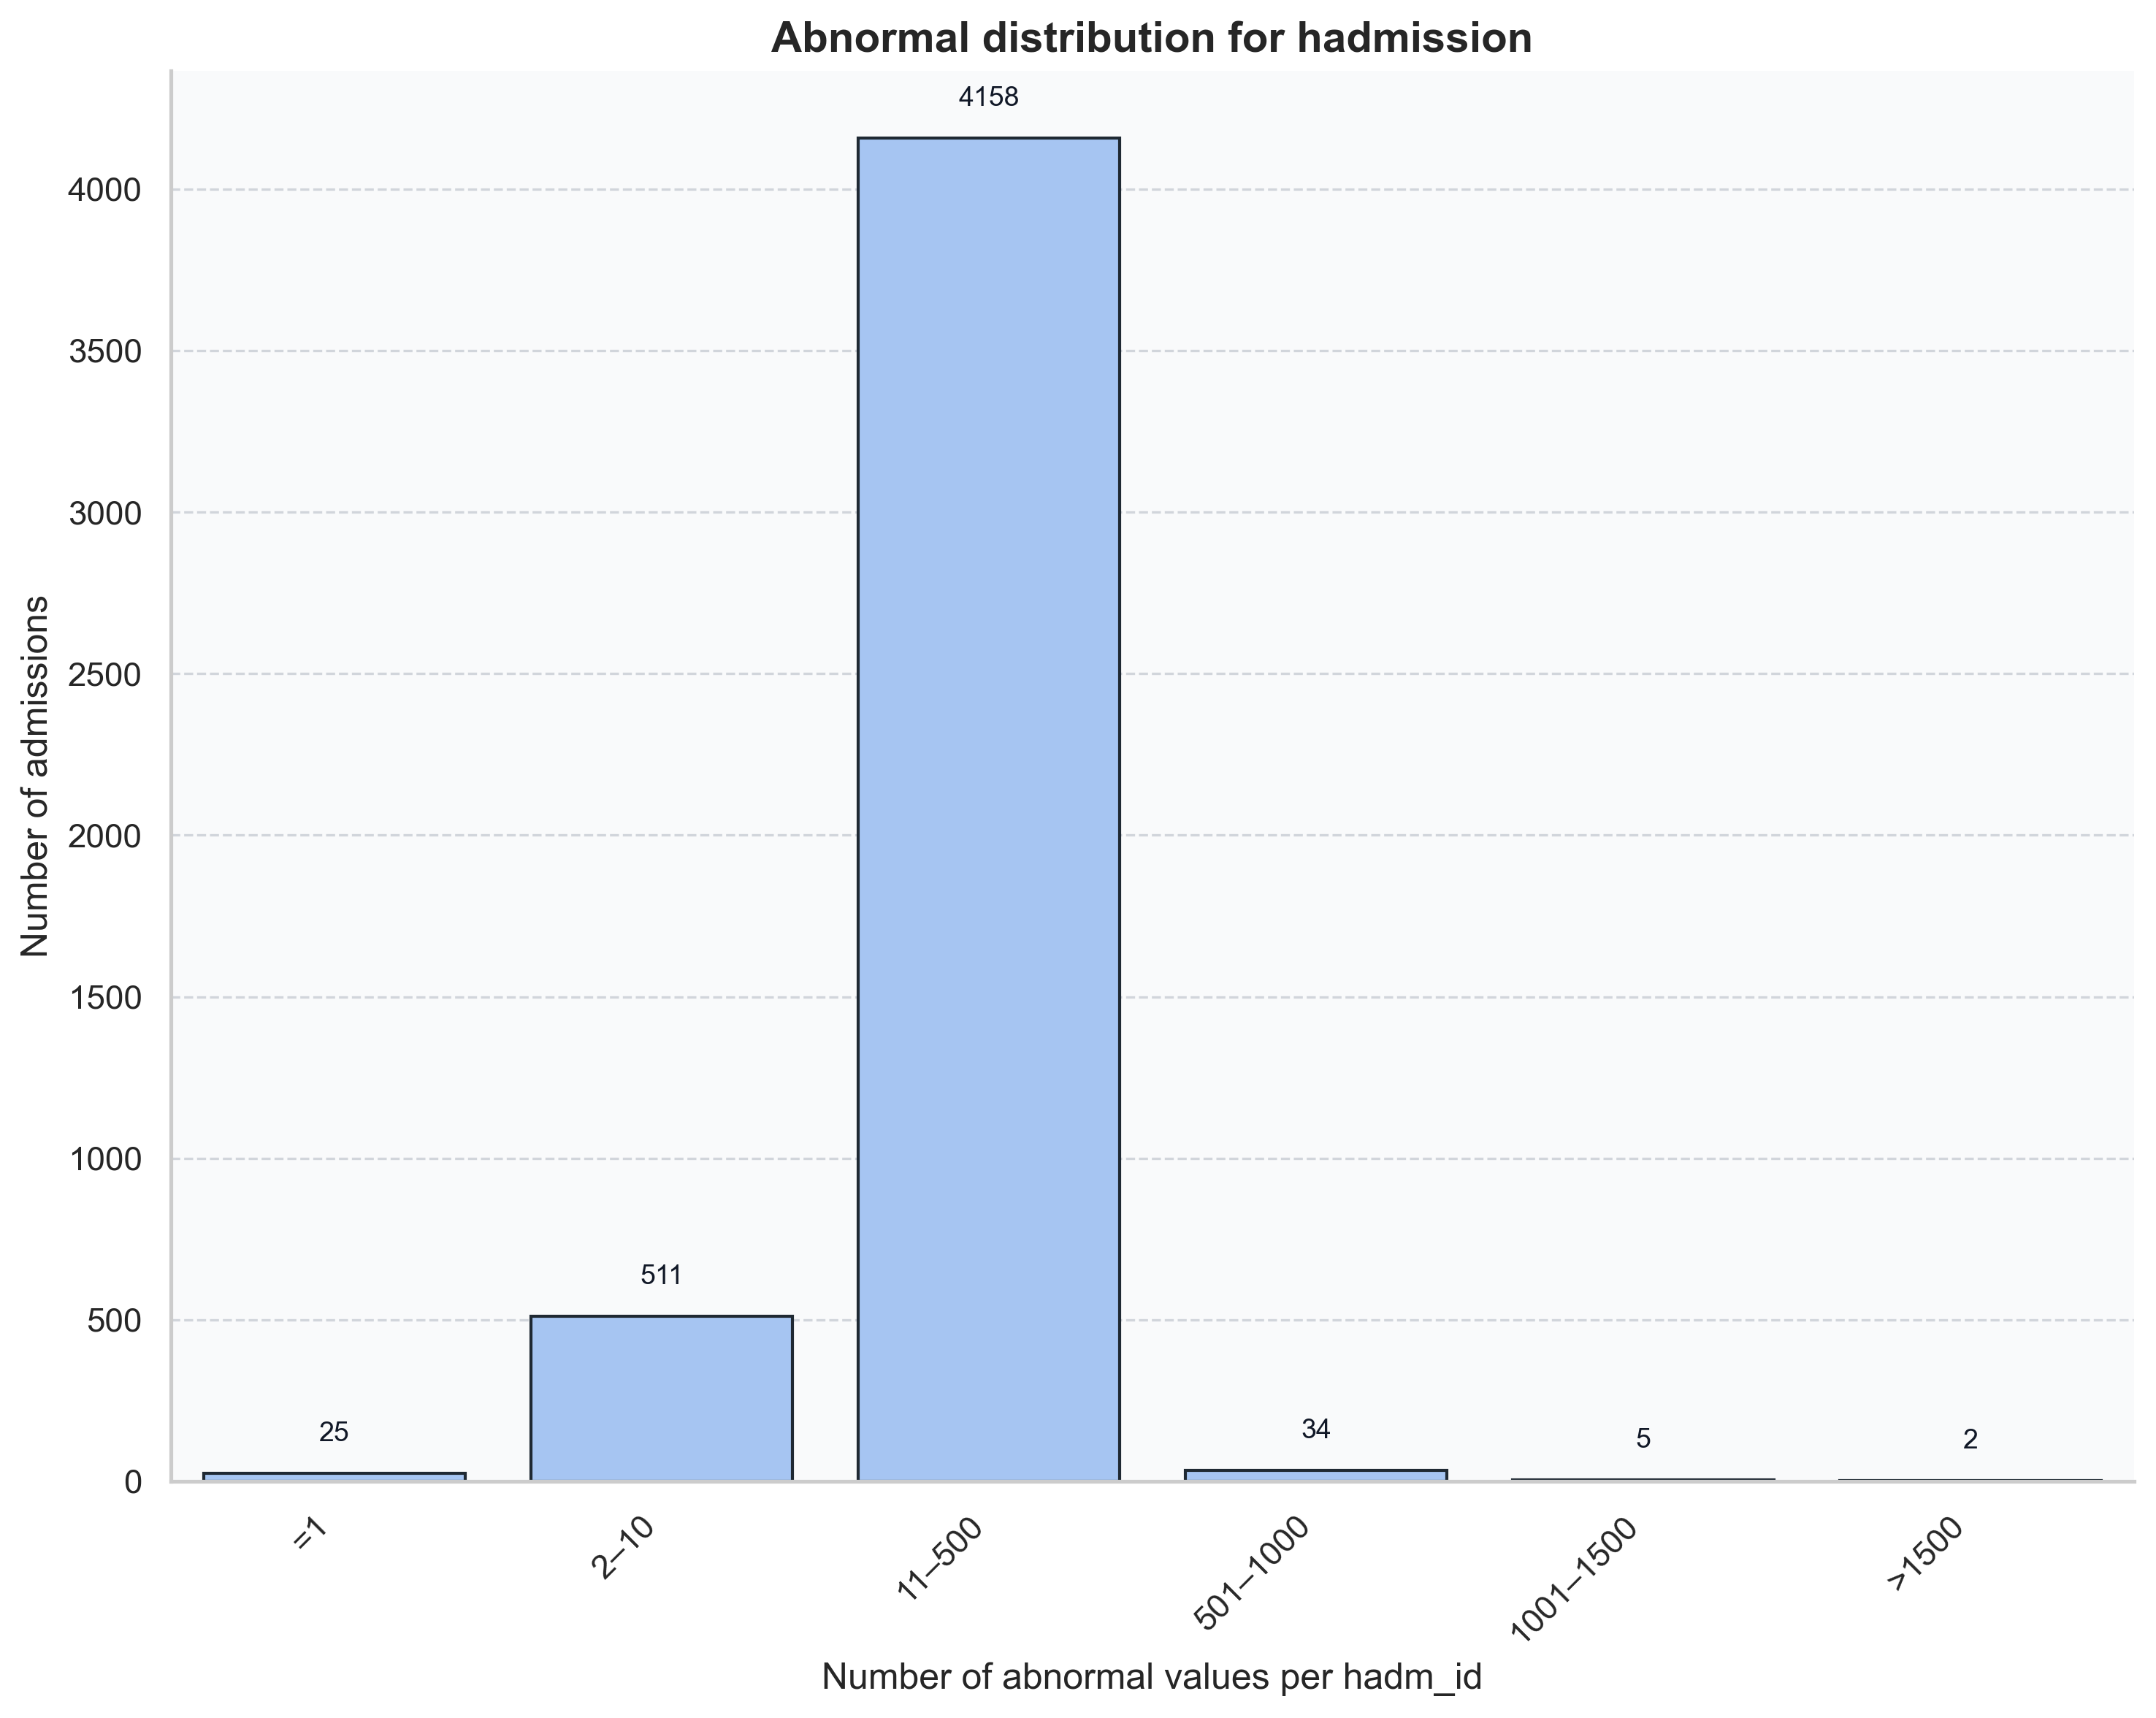

In [74]:
# Define the bins and labels for count ranges
bins = [0, 1, 10, 500, 1000, 1500, df_abnormal.max()]
labels = ["=1", "2–10", "11–500", "501–1000", "1001–1500", ">1500"]

# Reset index to get hadm_id as a column and count as another column
abnormal_counts = df_abnormal.reset_index()
abnormal_counts.columns = ["hadm_id", "count"]

# Bin the count values into specified ranges
abnormal_counts["count_bin"] = pd.cut(
    abnormal_counts["count"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Group by bin and count unique hadm_id in each bin
distribution_counts = (
    abnormal_counts.groupby("count_bin", observed=False)["hadm_id"]
    .nunique()
    .reindex(labels, fill_value=0)
    .reset_index(name="admissions")
)

# Plot configuration with seaborn and matplotlib
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#F9FAFB"})
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

bar = sns.barplot(
    data=distribution_counts,
    x="count_bin",
    y="admissions",
    color="#99c2ff",
    edgecolor="#1F2933"
)

# Title and axis labels
ax.set_title("Abnormal distribution for hadmission", fontsize=14, fontweight="bold")
ax.set_xlabel("Number of abnormal values per hadm_id")
ax.set_ylabel("Number of admissions")

# Grid and ticks styling
ax.grid(axis="y", color="#D1D5DB", linestyle="--", linewidth=0.8)
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")

sns.despine(ax=ax, top=True, right=True)

# Annotate bars with admission counts
for patch, (_, row) in zip(bar.patches, distribution_counts.iterrows()):
    ax.text(
        patch.get_x() + patch.get_width() / 2,
        patch.get_height() + max(distribution_counts["admissions"]) * 0.02,
        f"{row.admissions}",
        ha="center",
        va="bottom",
        fontsize=9,
        color="#111827"
    )

plt.tight_layout()
plt.show()


In [75]:
# Checks consistency between ref_range_lower and ref_range_upper
# Filters rows with inverted or equal reference ranges
inconsistent = data_frame[data_frame["ref_range_lower"] > data_frame["ref_range_upper"]]
equal_bounds = data_frame[data_frame["ref_range_lower"] == data_frame["ref_range_upper"]]

print(f"Inconsistent ranges: {len(inconsistent)}")
print(f"Equal lower/upper bounds: {len(equal_bounds)}")

Inconsistent ranges: 0
Equal lower/upper bounds: 5167


In [76]:
# Checks how many lab results fall outside their reference range
# Filters only rows with valid numeric values and reference limits
valid = data_frame.dropna(subset=["valuenum", "ref_range_lower", "ref_range_upper"])

# Selects those with valuenum below lower limit or above upper limit
outside = valid[
    (valid["valuenum"] < valid["ref_range_lower"]) |
    (valid["valuenum"] > valid["ref_range_upper"])
]

ratio = len(outside) / len(valid)
print(f"Out-of-range values: {len(outside)} / {len(valid)} ({ratio:.2%})")


Out-of-range values: 342373 / 855784 (40.01%)


In [77]:
correlation_matrix = du.get_correlation(data_frame)

if correlation_matrix is not None:
    print("Kendall correlation between numeric columns:\n")
    print(correlation_matrix)
else:
    print("Not enough numeric columns to calculate correlation.")


Kendall correlation between numeric columns:

                 valuenum  ref_range_lower  ref_range_upper
valuenum         1.000000         0.746494         0.832584
ref_range_lower  0.746494         1.000000         0.830795
ref_range_upper  0.832584         0.830795         1.000000


In [78]:
print("General dataset information:")
du.get_info(data_frame)

General dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 978503 entries, 0 to 978502
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   hadm_id            978503 non-null  float64
 1   charttime          978503 non-null  object 
 2   value              934025 non-null  object 
 3   valuenum           907317 non-null  float64
 4   valueuom           884585 non-null  object 
 5   ref_range_lower    865544 non-null  float64
 6   ref_range_upper    865544 non-null  float64
 7   flag               343687 non-null  object 
 8   label              978503 non-null  object 
 9   fluid              978503 non-null  object 
 10  examination_group  978503 non-null  object 
 11  analysis_batch_id  978503 non-null  object 
 12  qc_flag            978503 non-null  object 
 13  ref_range          146215 non-null  object 
dtypes: float64(4), object(10)
memory usage: 104.5+ MB


In [79]:
# Shows how many different units of measurement are present (mg/dL, mmol/L, etc.)
print("Distribution of measurement units (valueuom):\n")
print(data_frame["valueuom"].value_counts(dropna=False))


Distribution of measurement units (valueuom):

valueuom
mg/dL              229227
mEq/L              202759
%                  108847
NaN                 93918
K/uL                62265
g/dL                42846
sec                 42100
fL                  37094
m/uL                28489
pg                  28373
IU/L                25430
ng/mL               21768
mm Hg               14819
units               11320
mmol/L               9358
#/hpf                6590
                     2866
ug/dL                1700
pg/mL                1235
uIU/mL               1117
Ratio                1070
#/lpf                 947
ug/mL                 902
mOsm/kg               815
#/uL                  584
/hpf                  543
mg/L                  382
ng/dL                 352
L/min                 222
mm/hr                 154
IU/mL                  92
U/mL                   68
mg/mg                  66
+/-                    23
mg/24hr                22
ng/mL FEU              18
mL      

In [80]:
# Displays how many tests are flagged as abnormal
print("Abnormality flag counts (flag column):\n")
print(data_frame["flag"].value_counts(dropna=False))


Abnormality flag counts (flag column):

flag
NaN         634816
abnormal    343687
Name: count, dtype: int64


In [81]:
# Shows the number of tests performed for each fluid type (e.g., Blood, Urine, etc.)
print("Number of tests per fluid type:\n")
print(data_frame["fluid"].value_counts(dropna=False))

Number of tests per fluid type:

fluid
Blood                  918188
Urine                   56691
Pleural                  1881
Other Body Fluid         1350
Ascites                   188
Joint Fluid               141
Cerebrospinal Fluid        36
Stool                      15
Bone Marrow                13
Name: count, dtype: int64


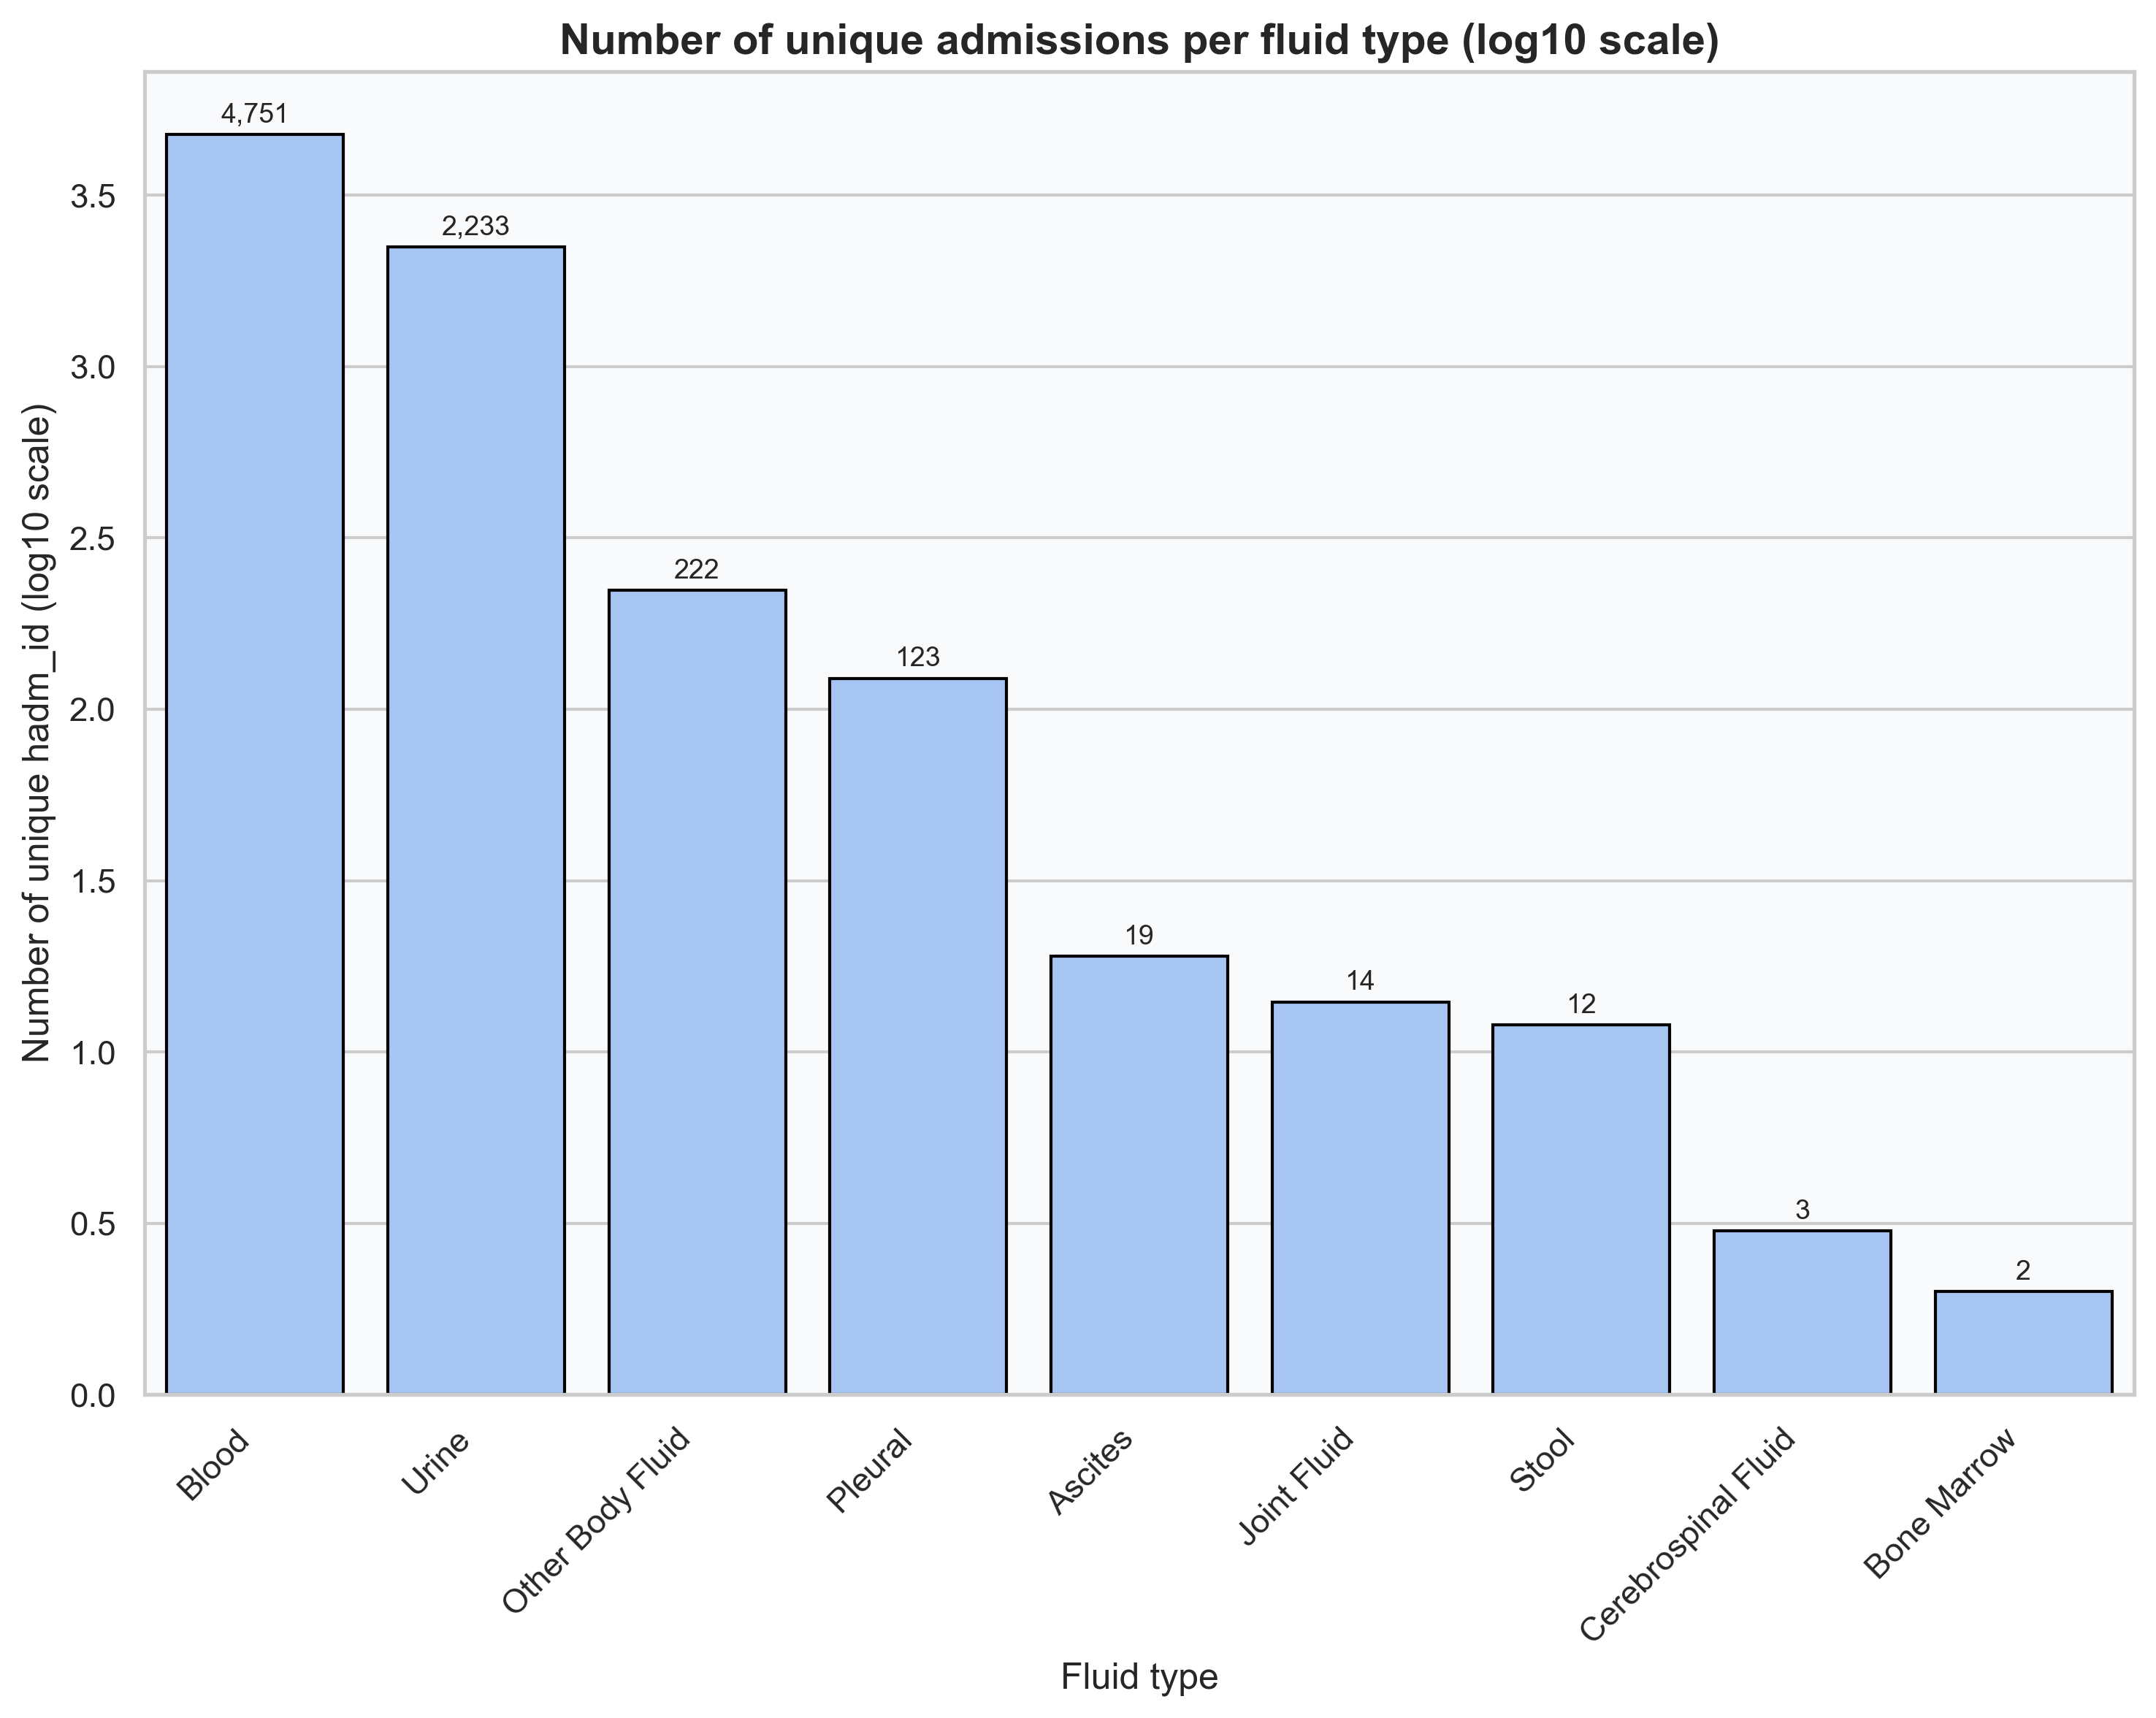

In [82]:
fluid_counts = (
    data_frame.groupby("fluid", dropna=False)["hadm_id"]
    .nunique()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
fluid_counts["log10_count"] = np.log10(fluid_counts["count"].replace(0, np.nan))

plt.figure(figsize=(10, 8), dpi=300)
ax = sns.barplot(
    data=fluid_counts,
    x="fluid",
    y="log10_count",
    color="#99c2ff",
    edgecolor="black",
)

ax.set_title("Number of unique admissions per fluid type (log10 scale)", fontsize=14, fontweight="bold")
ax.set_xlabel("Fluid type")
ax.set_ylabel("Number of unique hadm_id (log10 scale)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

for patch, (_, row) in zip(ax.patches, fluid_counts.iterrows()):
    if not np.isnan(row["log10_count"]):
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            row["log10_count"] + 0.02,
            f"{row['count']:,}",
            ha="center",
            va="bottom",
            fontsize=9,
        )
plt.tight_layout()
plt.show()

In [83]:
# frequencies list of laboratory test names in the dataset
print("frequencies list of laboratory test names:\n")
print(data_frame["label"].value_counts())


frequencies list of laboratory test names:

label
Glucose                   39744
Potassium                 37859
Sodium                    36712
Chloride                  36612
Creatinine                35939
                          ...  
Triglycerides, Ascites        1
EE5                           1
HPE5                          1
Urine Fat Bodies              1
Hematocrit, Ascites           1
Name: count, Length: 502, dtype: int64


In [84]:
# Shows basic descriptive statistics for the numeric test results (valuenum) grouped by lab test label
if "valuenum" in data_frame.columns and "label" in data_frame.columns:
    print("Descriptive statistics for 'valuenum' grouped by lab test label:\n")
    print(data_frame.groupby("label")["valuenum"].describe())
else:
    print("Columns 'valuenum' or 'label' not found in the dataset.")

Descriptive statistics for 'valuenum' grouped by lab test label:

                    count         mean          std    min      25%      50%  \
label                                                                          
% Hemoglobin A1c   1080.0     6.510648     1.545272    4.0     5.60     6.00   
24 hr Calcium         1.0   122.000000          NaN  122.0   122.00   122.00   
24 hr Creatinine     14.0  1110.285714   652.013618   75.0   752.25   940.50   
24 hr Protein         7.0   233.714286   132.658351   84.0   149.50   185.00   
25-OH Vitamin D      30.0    33.066667    19.704600    7.0    20.25    31.00   
...                   ...          ...          ...    ...      ...      ...   
pCO2               7320.0    42.196995    11.199869   10.0    35.00    40.00   
pH                11320.0     7.000967     0.775802    1.0     7.11     7.37   
pO2                7330.0   142.997544   102.121934   16.0    77.00   108.00   
proBNP, Pleural      11.0  4370.000000  3794.452556  2

In [85]:
#analysis of valuenum for each label 
value=data_frame.groupby("label")["valuenum"].describe()
value=value[['min','max']]
value

,min,max
label,,
% Hemoglobin A1c,4.0,18.9
24 hr Calcium,122.0,122.0
24 hr Creatinine,75.0,2295.0
24 hr Protein,84.0,462.0
25-OH Vitamin D,7.0,92.0
...,...,...
pCO2,10.0,144.0
pH,1.0,9.0
pO2,16.0,600.0


In [86]:
# Displays how many lab results have each qc_flag status (OK, WARN, FAIL)
print("Quality control flag distribution:\n")
print(data_frame["qc_flag"].value_counts(dropna=False))


Quality control flag distribution:

qc_flag
OK      880809
WARN     78124
FAIL     19570
Name: count, dtype: int64


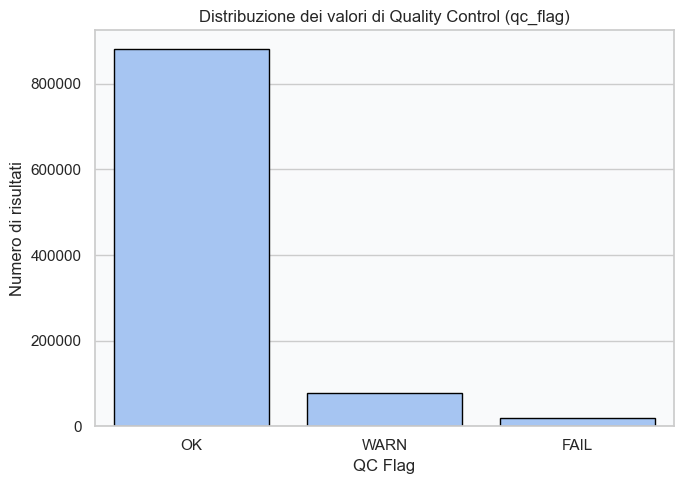

In [87]:
qc_counts = data_frame["qc_flag"].value_counts(dropna=False)

qc_df = qc_counts.reset_index()
qc_df.columns = ["qc_flag", "count"]

plt.figure(figsize=(7,5))
sns.barplot(data=qc_df, x="qc_flag", y="count", color="#99c2ff", edgecolor="black")

plt.title("Distribuzione dei valori di Quality Control (qc_flag)")
plt.xlabel("QC Flag")
plt.ylabel("Numero di risultati")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [88]:
# Shows how many missing entries are in valuenum, ref_range_lower, and ref_range_upper
key_cols = ["valuenum", "ref_range_lower", "ref_range_upper"]
print("Missing values in key numeric columns:\n")
print(data_frame[key_cols].isnull().sum())


Missing values in key numeric columns:

valuenum            71186
ref_range_lower    112959
ref_range_upper    112959
dtype: int64


# PLOT 

In [89]:
#per avere il numero per range preciso se puo interessarci (resa visiva due celle sotto)

bins = [0, 50, 100, 200, 300, 500, 1000, 5000, data_frame["valuenum"].max()]
labels = ["0-50", "50-100", "100-200", "200-300", "300-500", "500-1000", "1000-5000", "5000+"]

data_frame["valuenum_range"] = pd.cut(data_frame["valuenum"], bins=bins, labels=labels, include_lowest=True)
counts = data_frame["valuenum_range"].value_counts().sort_index()

print("Conteggio dei valori per intervallo:")
print(counts)


Conteggio dei valori per intervallo:
valuenum_range
0-50         664884
50-100        97446
100-200      107864
200-300       18933
300-500       10005
500-1000       3034
1000-5000      1680
5000+           542
Name: count, dtype: int64


analisi personale (e banale) di Sara: La distribuzione dei risultati di laboratorio è fortemente sbilanciata: oltre il 70 % dei valori numerici si concentra sotto 50 e quasi il 96 % sotto 300.
Le code alte (oltre 1000, per un massimo di 900000) rappresentano meno dello 0.5 % dei casi e possono essere considerate outlier o dovute a unità di misura differenti.

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_21988\3508888537.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


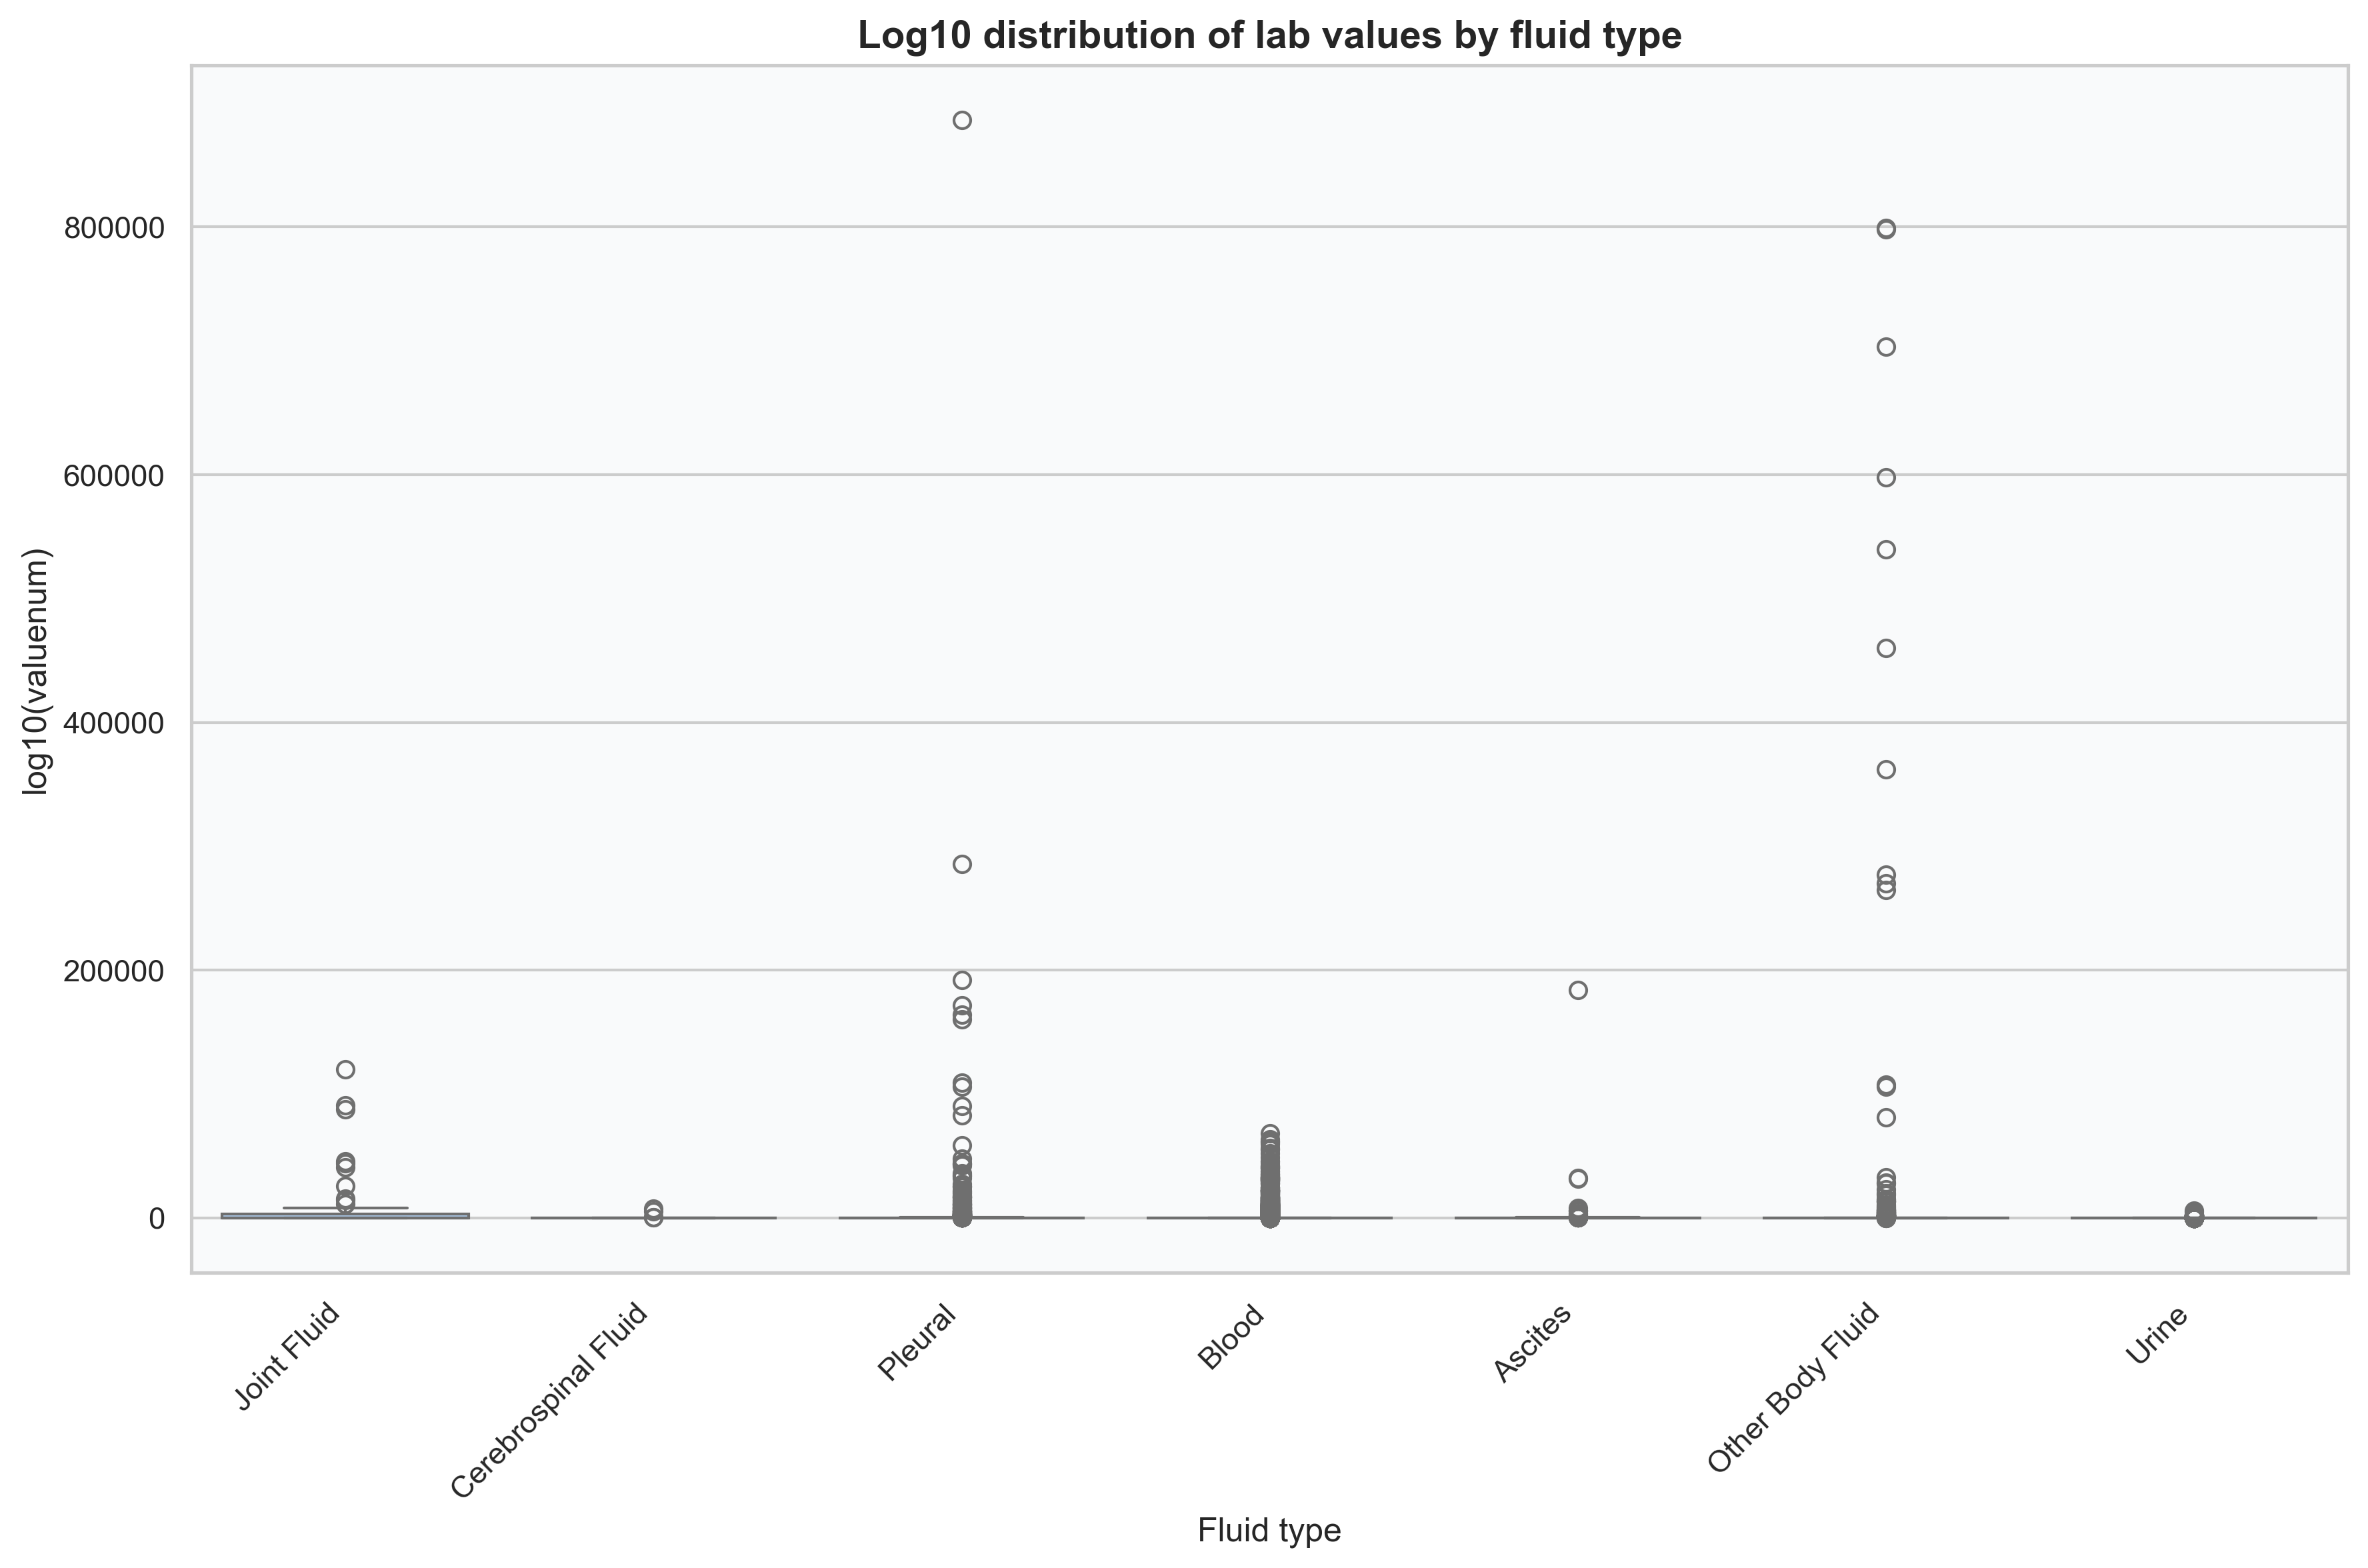

In [90]:
#secondo ilaria questo grafico non ha senso
plot_df = (
    data_frame.dropna(subset=["fluid", "valuenum"])
    .loc[lambda df: df["valuenum"] > 0]
)

fluid_order = (
    plot_df.groupby("fluid")["valuenum"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 8), dpi=300)
ax = sns.boxplot(
    data=plot_df,
    x="fluid",
    y=plot_df["valuenum"],
    order=fluid_order,
    palette="pastel",
    showfliers=True,
)

ax.set_title("Log10 distribution of lab values by fluid type", fontsize=14, fontweight="bold")
ax.set_xlabel("Fluid type")
ax.set_ylabel("log10(valuenum)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()


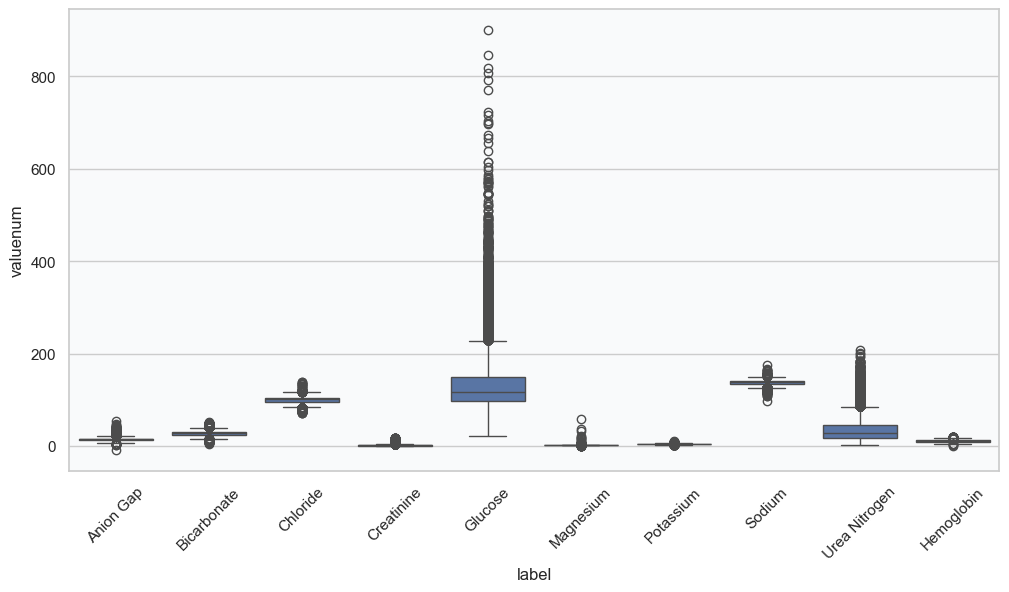

In [91]:
#dato che analizzeremo solo il blood alla fine , mi sofferemrei su quello e guaderei i valoir per esame


# Filtra solo gli esami sul fluido sangue
blood_df = data_frame[data_frame['fluid'] == 'Blood']
import seaborn as sns
import matplotlib.pyplot as plt

# Conta quante osservazioni per ogni esame
counts = blood_df['label'].value_counts().head(10).index

# Filtra solo i top 10 esami
subset = blood_df[blood_df['label'].isin(counts)]

plt.figure(figsize=(12,6))
sns.boxplot(x='label', y='valuenum', data=subset)
plt.xticks(rotation=45)
plt.show()





Distribuzione per fasce del numero di valori anomali per ammissione:
count_bin
=1             25
2–10          511
11–500       4158
501–1000       34
1001–1500       5
>1500           2
Name: admissions, dtype: int64


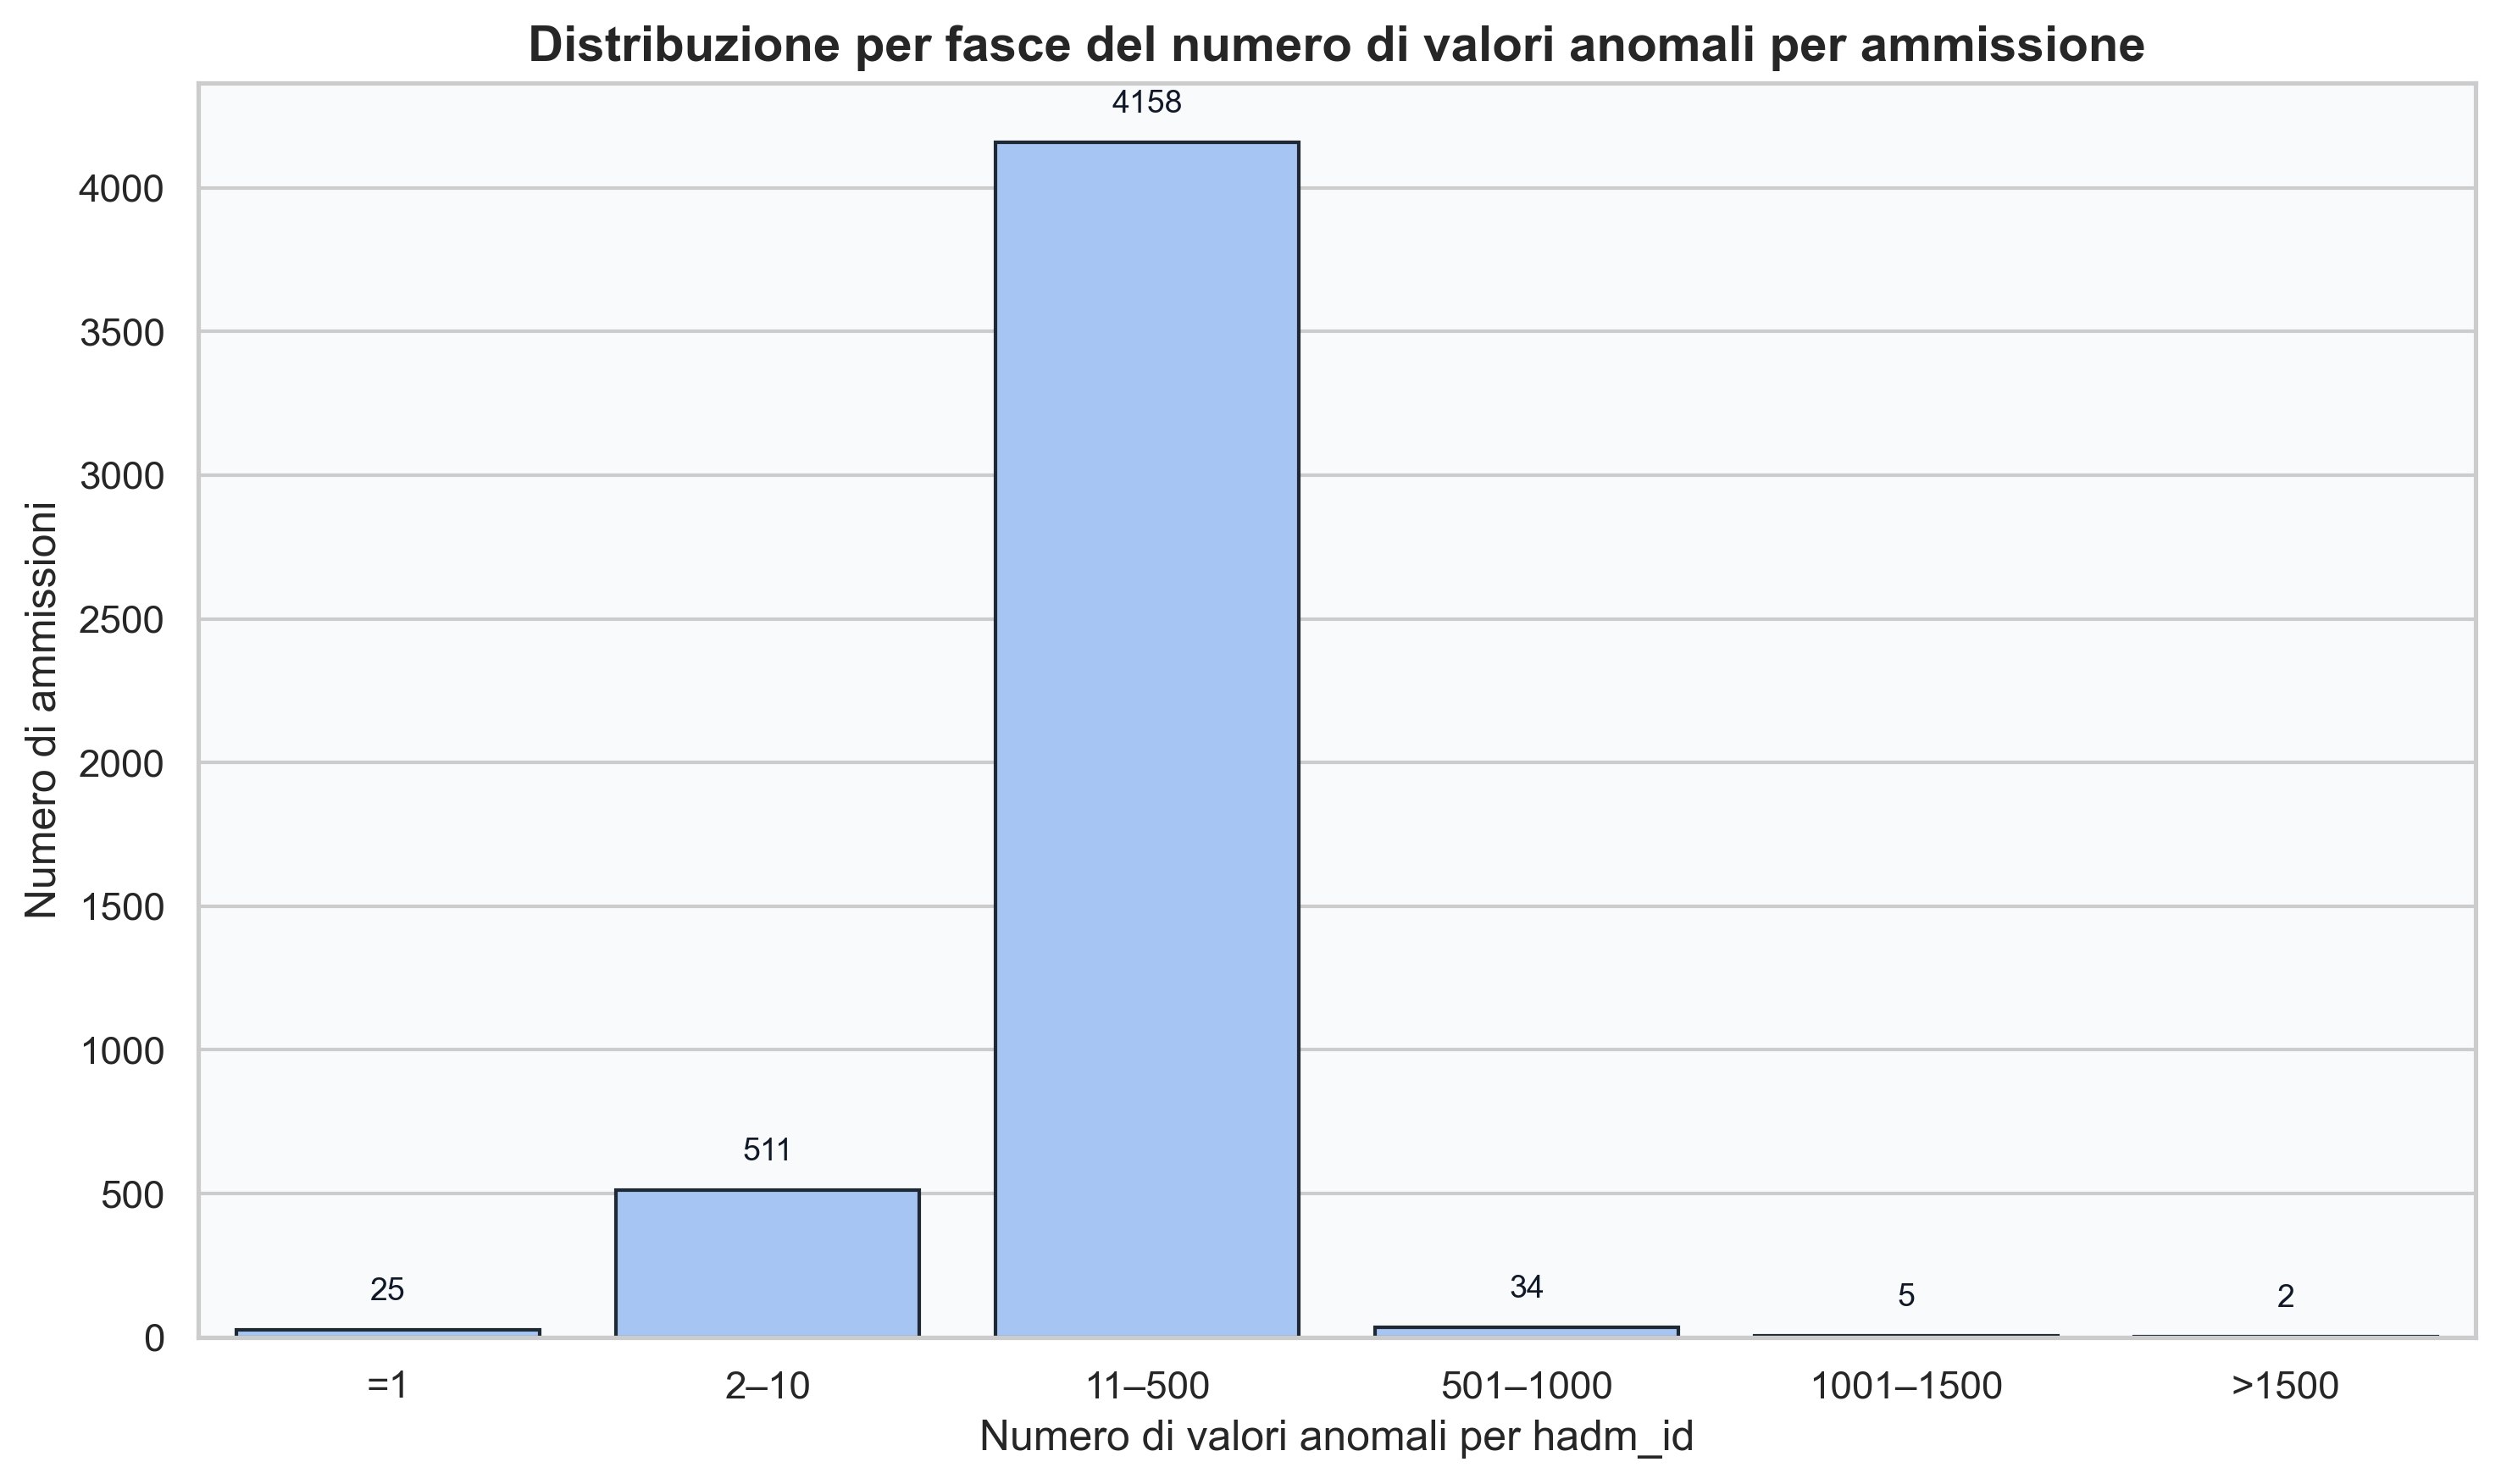

In [92]:
bin_edges = [0, 1, 10, 500, 1000, 1500, np.inf]
bin_labels = ["=1", "2–10", "11–500", "501–1000", "1001–1500", ">1500"]

abnormal_counts = (
    df_abnormal.reset_index()
    .rename(columns={0: "count"})
    .drop_duplicates(subset=["hadm_id"])
)
abnormal_counts["count_bin"] = pd.cut(
    abnormal_counts["count"],
    bins=bin_edges,
    labels=bin_labels,
    include_lowest=True,
    right=True,
)

distribution_counts = (
    abnormal_counts.groupby("count_bin", observed=False)["hadm_id"]
    .nunique()
    .reindex(bin_labels, fill_value=0)
    .reset_index(name="admissions")
)

print("Distribuzione per fasce del numero di valori anomali per ammissione:")
print(distribution_counts.set_index("count_bin")["admissions"])

plt.figure(figsize=(10, 6), dpi=300)
bar = sns.barplot(
    data=distribution_counts,
    x="count_bin",
    y="admissions",
    color="#99c2ff",
    edgecolor="#1F2933",
)

plt.title("Distribuzione per fasce del numero di valori anomali per ammissione", fontsize=14, fontweight="bold")
plt.xlabel("Numero di valori anomali per hadm_id")
plt.ylabel("Numero di ammissioni")
plt.xticks(rotation=0)

max_height = distribution_counts["admissions"].max()
for patch, (_, row) in zip(bar.patches, distribution_counts.iterrows()):
    height = patch.get_height()
    ax_y = height + (0.02 * max_height if height > 0 else max_height * 0.02)
    bar.annotate(
        f"{row.admissions}",
        (patch.get_x() + patch.get_width() / 2, ax_y),
        ha="center",
        va="bottom",
        fontsize=9,
        color="#111827",
    )

plt.tight_layout()
plt.show()